# Explorare - Tema 1 CAVA

In [60]:
%load_ext autoreload
%autoreload 2

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

from utils import show_image, deseneaza_puncte
from tabla import extrage_careu, detecteaza_template, calculeaza_celule
from culori import CULORI, H, decupeaza_piesa, masca_simbol, hue_piesa, antreneaza_hue, clasifica_culoare

DATE = 'CAVA-2026-TEMA1'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


(3720, 1844, 3)


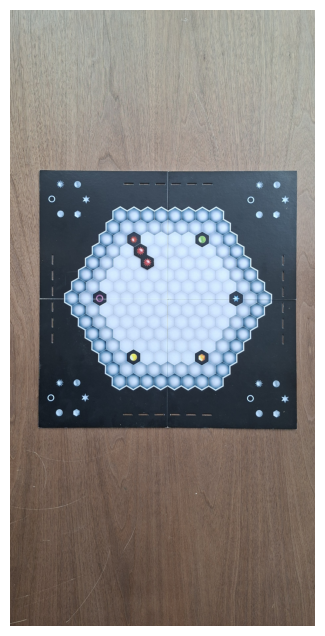

In [3]:
img = cv.imread(os.path.join(DATE, 'antrenare/table-joc/1_01.jpg'))
print(img.shape)
show_image(img)

## Extragerea tablei: `extrage_careu` (in tabla.py)

In [ ]:
rezultat = extrage_careu(img, debug=True)
show_image(rezultat, 'rezultat')

In [ ]:
nume = ['1_01', '2_20', '3_10', '4_07', '5_20']
decupaje = [extrage_careu(cv.imread(os.path.join(DATE, 'antrenare/table-joc', n + '.jpg'))) for n in nume]
show_image(np.hstack(decupaje), ' | '.join(nume), size=(20, 5))

## Detectarea celulelor pe tabla goala (matchTemplate, in tabla.py)

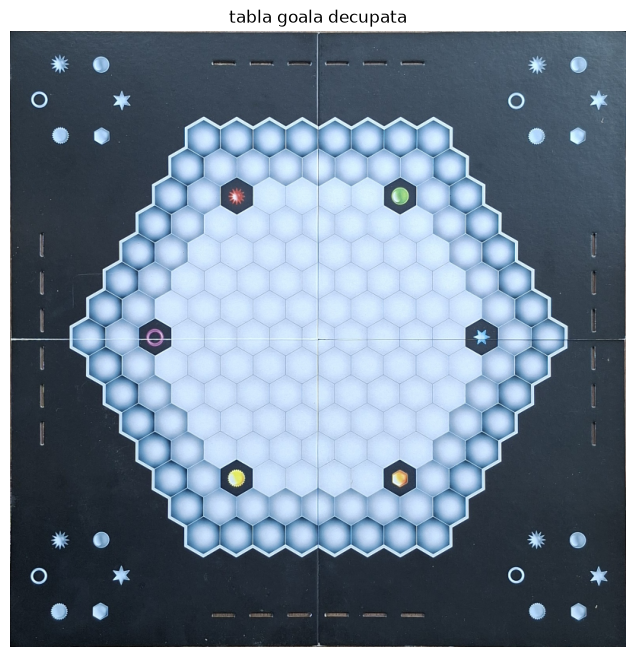

In [57]:
tabla_goala = extrage_careu(cv.imread(os.path.join(DATE, 'imagini_auxiliare/tabla_joc_1.jpg')))
gray_goala = cv.cvtColor(tabla_goala, cv.COLOR_BGR2GRAY)
show_image(tabla_goala, 'tabla goala decupata')

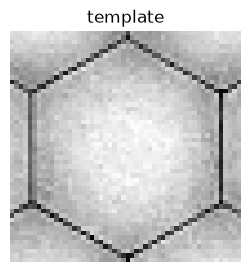

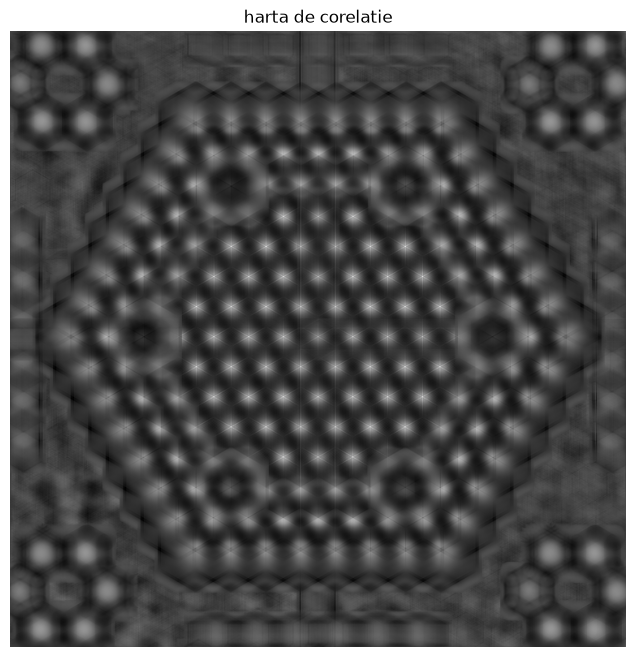

detectii brute: 139


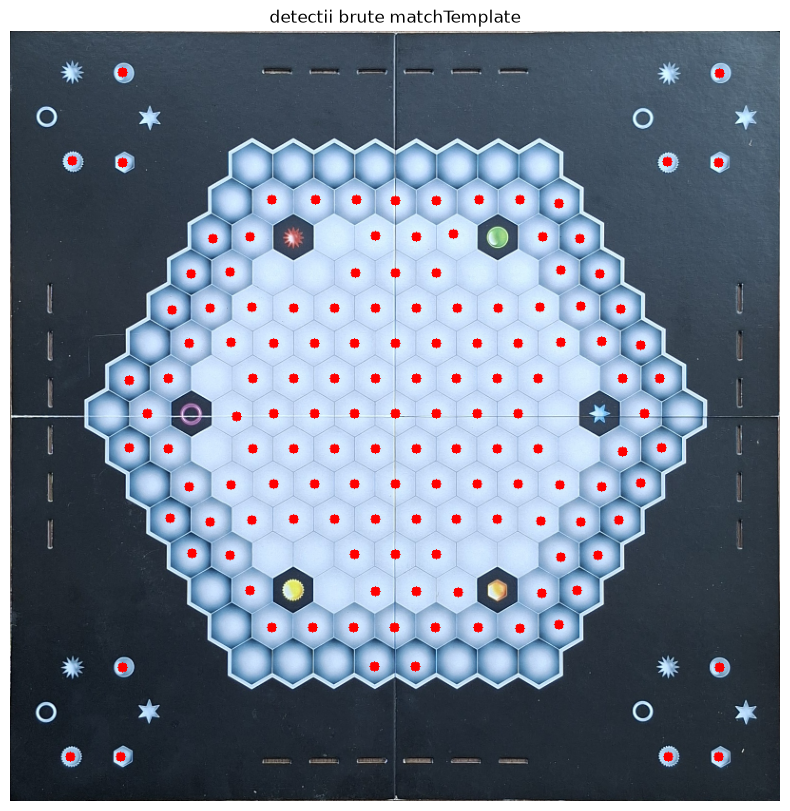

In [58]:
puncte_template = detecteaza_template(gray_goala, (341, 291), debug=True)
print('detectii brute:', len(puncte_template))
deseneaza_puncte(tabla_goala, puncte_template, 'detectii brute matchTemplate')

(85, 2)


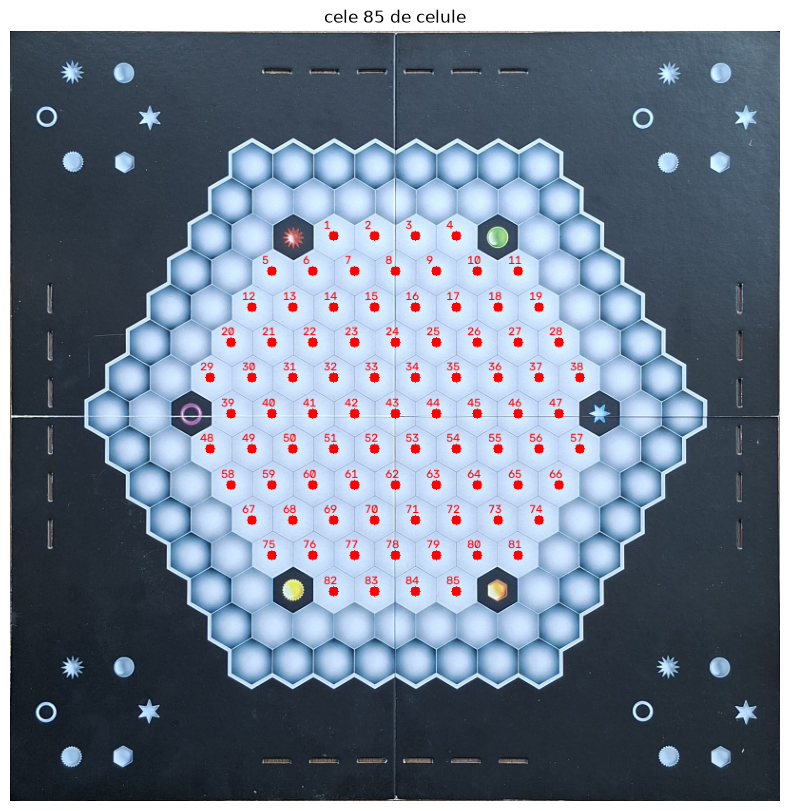

In [61]:
CELULE = calculeaza_celule(tabla_goala)
print(CELULE.shape)
deseneaza_puncte(tabla_goala, CELULE, 'cele 85 de celule', etichete=True)

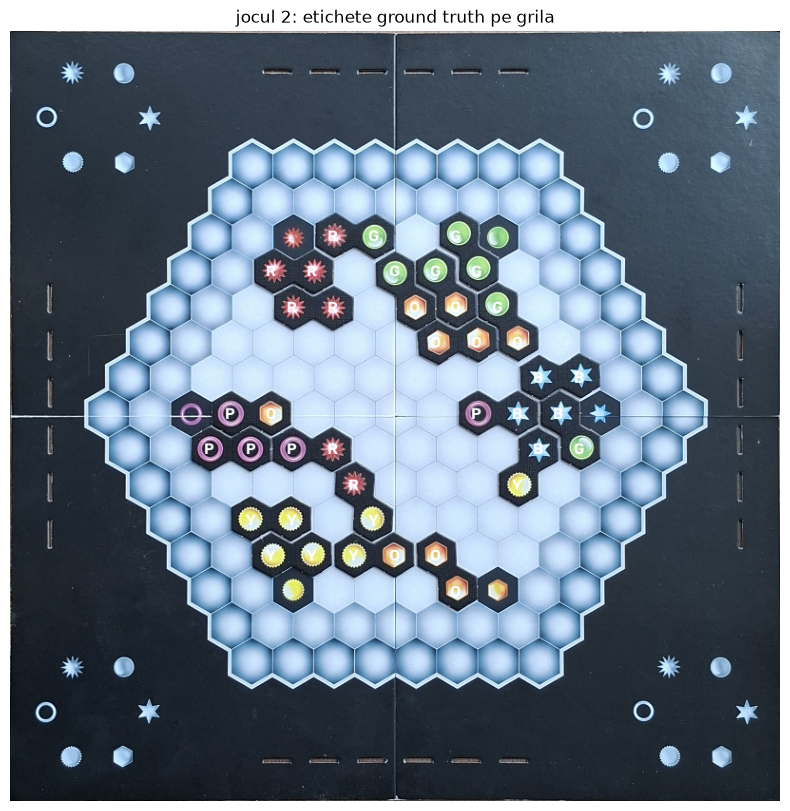

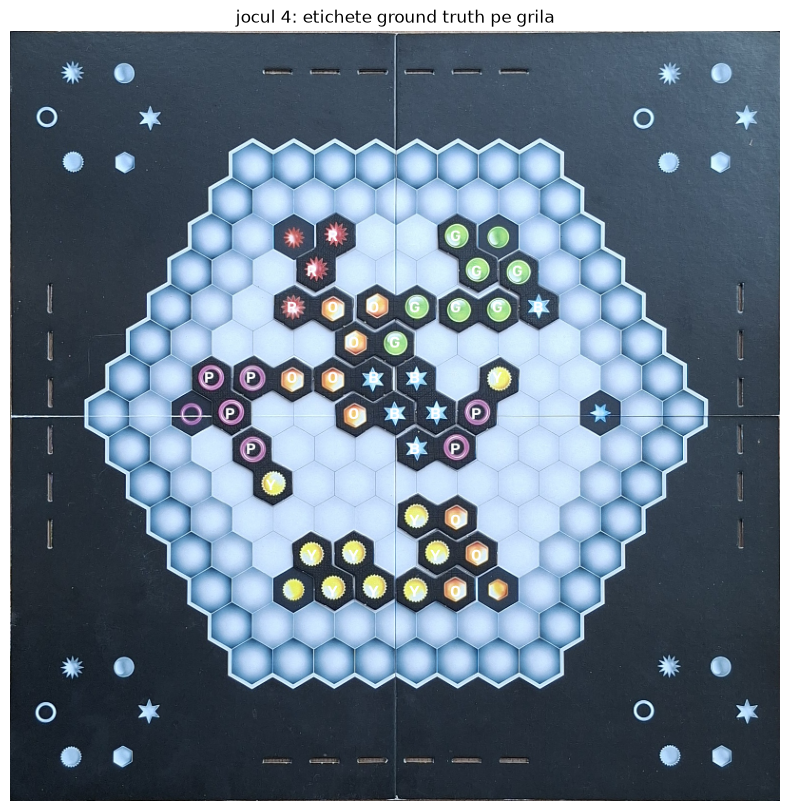

In [62]:
def verifica_ground_truth(joc, celule):
    tabla = extrage_careu(cv.imread(os.path.join(DATE, f'antrenare/table-joc/{joc}_20.jpg')))
    for i in range(1, 21):
        with open(os.path.join(DATE, f'antrenare/table-joc/{joc}_{i:02d}.txt')) as f:
            linii = f.read().split('\n')[:2]
        for linie in linii:
            pozitie, culoare = linie.split()
            x, y = celule[int(pozitie) - 1]
            cv.putText(tabla, culoare, (int(x) - 6, int(y) + 6), cv.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
    show_image(tabla, f'jocul {joc}: etichete ground truth pe grila', size=(10, 10))

verifica_ground_truth(2, CELULE)
verifica_ground_truth(4, CELULE)

## Clasificarea culorilor pieselor noi

Setul de date: cele 2 piese noi din fiecare imagine de antrenare (5 jocuri × 20 mutări × 2 = 200 de piese), decupate 48×48 în jurul centrului celulei.

In [ ]:
def citeste_piese(director, director_etichete=None):
    director_etichete = director_etichete or director
    piese, etichete, jocuri = [], [], []
    for nume in sorted(os.listdir(director)):
        if not nume.endswith('.jpg'):
            continue
        tabla = extrage_careu(cv.imread(os.path.join(director, nume)))
        with open(os.path.join(director_etichete, nume.replace('.jpg', '.txt'))) as f:
            linii = f.read().split('\n')[:2]
        for linie in linii:
            pozitie, culoare = linie.split()
            piese.append(decupeaza_piesa(tabla, CELULE[int(pozitie) - 1]))
            etichete.append(culoare)
            jocuri.append(int(nume.split('_')[0]))
    return np.array(piese), np.array(etichete), np.array(jocuri)


PIESE, ETICHETE, JOCURI = citeste_piese(os.path.join(DATE, 'antrenare/table-joc'))
print(PIESE.shape, {c: int((ETICHETE == c).sum()) for c in CULORI})

montaj = np.vstack([np.hstack(PIESE[ETICHETE == c][:12]) for c in CULORI])
show_image(montaj, 'cate 12 piese din fiecare culoare: ' + ' / '.join(CULORI), size=(12, 6))

### Clasificare după culoare (HSV, Laboratorul 7)

Din fiecare petic se păstrează doar pixelii simbolului: disc de rază 15 în jurul centrului (scapă de fundalul tablei din colțuri), S > 60 (scapă de reflexiile albe și de fundalul albăstrui), V > 60 (scapă de negrul piesei). Pe pixelii rămași se ia mediana Hue-ului.

Roșul e la capătul intervalului Hue (0 și 180) → Hue-ul se deplasează cu +20 (mod 180), ca toate valorile roșului să fie grupate.

Implementare: `culori.py`.

In [ ]:
exemple = [PIESE[ETICHETE == c][0] for c in CULORI]
vis = [np.where(masca_simbol(p)[0][:, :, None], p, 0) for p in exemple]
show_image(np.vstack([np.hstack(exemple), np.hstack(vis)]), 'sus: piesa / jos: pixelii folositi pentru culoare', size=(12, 4))

In [ ]:
HUE = np.array([hue_piesa(p) for p in PIESE])

plt.figure(figsize=(10, 3))
for c in CULORI:
    plt.hist(HUE[ETICHETE == c], bins=np.arange(0, 181, 1), label=c)
plt.xlabel('Hue median (deplasat cu +20)')
plt.legend()
plt.show()

for c in CULORI:
    h = HUE[ETICHETE == c]
    print(f'{c}: min {h.min():5.1f}  mediana {np.median(h):5.1f}  max {h.max():5.1f}')

### Evaluare: leave-one-game-out

Pentru fiecare joc g: referințele se calculează din celelalte 4 jocuri, se testează pe jocul g. Așa nicio piesă nu e clasificată folosind propria ei imagine.

In [ ]:
def leave_one_game_out(antreneaza, clasifica):
    predictii = np.empty_like(ETICHETE)
    for g in np.unique(JOCURI):
        model = antreneaza(PIESE[JOCURI != g], ETICHETE[JOCURI != g])
        predictii[JOCURI == g] = [clasifica(p, model) for p in PIESE[JOCURI == g]]
    return predictii


def matrice_confuzie(adevarat, prezis, titlu):
    m = np.array([[np.sum((adevarat == a) & (prezis == p)) for p in CULORI] for a in CULORI])
    print(f'{titlu}: {np.sum(adevarat == prezis)}/{len(adevarat)} corecte')
    print('     ' + '  '.join(CULORI) + '   <- prezis')
    for a, rand in zip(CULORI, m):
        print(f'  {a}  ' + '  '.join(str(v) for v in rand))
    print()


pred_hue = leave_one_game_out(antreneaza_hue, clasifica_culoare)
matrice_confuzie(ETICHETE, pred_hue, 'HSV')

### Marginea de siguranță

Acuratețea nu spune tot: contează cât de aproape a fost a doua variantă. Marginea = distanța până la a doua referință minus distanța până la prima (în unități Hue). Margini mici = clasificări fragile.

In [ ]:
ref = antreneaza_hue(PIESE, ETICHETE)

margini = []
for p in PIESE:
    d = sorted(abs(hue_piesa(p) - r) for r in ref.values())
    margini.append(d[1] - d[0])

plt.figure(figsize=(6, 3))
plt.hist(margini, bins=30)
plt.title('diferenta de distanta Hue (unitati Hue)')
plt.show()
print('referinte Hue:', {c: float(v) for c, v in ref.items()})
print('marginea minima:', min(margini))

### Test final pe `fake_test` (date nevăzute)

Referințele: toate cele 200 de piese de antrenare.

In [ ]:
PIESE_FT, ETICHETE_FT, _ = citeste_piese(os.path.join(DATE, 'evaluare/fake_test/table-joc'),
                                         os.path.join(DATE, 'evaluare/fisiere_solutie/fake-test-ground-truth'))

matrice_confuzie(ETICHETE_FT, np.array([clasifica_culoare(p, ref) for p in PIESE_FT]), 'fake_test HSV')

## Detectarea pieselor noi

O celulă e ocupată dacă media canalului V (HSV) pe discul din jurul centrului e mică: celulele libere sunt aproape albe, piesele sunt negre.

In [ ]:
from piese import PRAG_V_OCUPAT, luminozitate_celule, celule_ocupate, piese_noi_absolut

DIR_JOC = os.path.join(DATE, 'antrenare/table-joc')


def citeste_mutare(director, joc, i):
    with open(os.path.join(director, f'{joc}_{i:02d}.txt')) as f:
        return sorted(int(l.split()[0]) - 1 for l in f.read().split('\n')[:2])


V_OCUPAT, V_LIBER = [], []
for g in range(1, 6):
    ocupate = set()
    for i in range(1, 21):
        tabla = extrage_careu(cv.imread(os.path.join(DIR_JOC, f'{g}_{i:02d}.jpg')))
        ocupate |= set(citeste_mutare(DIR_JOC, g, i))
        v = luminozitate_celule(tabla, CELULE)
        masca = np.isin(np.arange(85), list(ocupate))
        V_OCUPAT += list(v[masca])
        V_LIBER += list(v[~masca])

plt.figure(figsize=(10, 3))
plt.hist(V_OCUPAT, bins=np.arange(100, 256, 2), label='ocupate')
plt.hist(V_LIBER, bins=np.arange(100, 256, 2), label='libere')
plt.axvline(PRAG_V_OCUPAT, color='k', linestyle='--', label='prag')
plt.xlabel('media V pe disc')
plt.legend()
plt.show()
print(f'ocupate: max {max(V_OCUPAT):.1f}   libere: min {min(V_LIBER):.1f}')

In [ ]:
tabla = extrage_careu(cv.imread(os.path.join(DIR_JOC, '2_10.jpg')))
deseneaza_puncte(tabla, CELULE[celule_ocupate(tabla, CELULE)], '2_10: celule detectate ca ocupate')

### Piesele noi: varianta A (absolut) + constrângerea de vecinătate

O piesă ocupă mereu 2 celule vecine. Se iau toate perechile de celule vecine (distanță 1 în coordonate hexagonale (q, r)) în care ambele celule erau libere înainte și se alege perechea cu suma V minimă. Starea „ocupat” se ține minte din predicțiile anterioare.

Marginea = diferența de scor dintre a 2-a și prima pereche candidată (cât de aproape a fost o greșeală).

In [ ]:
from tabla import perechi_vecine
import glob

PERECHI_VECINE = {tuple(p) for p in perechi_vecine()}
print('perechi de celule vecine pe tabla:', len(PERECHI_VECINE))

for director in [DIR_JOC, os.path.join(DATE, 'evaluare/fisiere_solutie/fake-test-ground-truth')]:
    fisiere = sorted(glob.glob(os.path.join(director, '[0-9]_[0-9][0-9].txt')))
    vecine = sum(tuple(citeste_mutare(director, *map(int, os.path.basename(f)[:-4].split('_')))) in PERECHI_VECINE for f in fisiere)
    print(f'{director}: {vecine}/{len(fisiere)} piese pe celule vecine')

In [ ]:
def evalueaza_piese_noi(director, director_etichete, jocuri):
    corecte, margini, n = 0, [], 0
    for g in jocuri:
        ocupate = np.zeros(85, bool)
        for i in range(1, 21):
            tabla = extrage_careu(cv.imread(os.path.join(director, f'{g}_{i:02d}.jpg')))
            noi, scor = piese_noi_absolut(tabla, ocupate, CELULE)
            s = np.sort(scor)
            margini.append(s[1] - s[0])
            corecte += list(noi) == citeste_mutare(director_etichete, g, i)
            ocupate[noi] = True
            n += 1
    print(f'{corecte}/{n} mutari corecte   margine minima {min(margini):5.1f}')


evalueaza_piese_noi(DIR_JOC, DIR_JOC, range(1, 6))
evalueaza_piese_noi(os.path.join(DATE, 'evaluare/fake_test/table-joc'),
                    os.path.join(DATE, 'evaluare/fisiere_solutie/fake-test-ground-truth'), [1])